# Ninapro DB3 sEMG: EDA (A–H) + Related Work
**Course:** CSE475 Machine Learning — Track 1 (GNN on Table-Style Data) | **Group 02**

## 0. Setup & Environment

In [1]:
!pip install -q umap-learn plotly

import os, re, shutil, subprocess, urllib.request, warnings
import numpy as np
import pandas as pd
import scipy.io as sio
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from scipy.stats import skew, kurtosis
from numpy.lib.stride_tricks import sliding_window_view
from sklearn.preprocessing import RobustScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import f1_score, silhouette_score
import umap

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)
sns.set_theme(style='whitegrid')

ZIP_DIR = '/content/Ninapro_Zips'
LOCAL_DIR = '/content/Ninapro_DB3'
os.makedirs(ZIP_DIR, exist_ok=True)
os.makedirs(LOCAL_DIR, exist_ok=True)
print('Local directory:', LOCAL_DIR)

Local directory: /content/Ninapro_DB3


## 1. Download & Extract Ninapro DB3 Zip Files (No Google Drive Required)
Directly downloads `s1_0.zip` through `s11_0.zip` from the official Ninapro repository into Colab local storage and extracts all 33 `.mat` files.

In [2]:

BASE_URL = 'https://ninapro.hevs.ch/files/db3_Preproc'
failed_zips = []

for s in range(1, 12):
    zf = f's{s}_0.zip'
    zip_path = os.path.join(ZIP_DIR, zf)

    if not os.path.exists(zip_path) or os.path.getsize(zip_path) < 1000:
        url = f'{BASE_URL}/{zf}'
        print(f'Downloading {zf} from {url} ...')
        r_dl = subprocess.run(['wget', '-q', '-c', url, '-O', zip_path])
        if r_dl.returncode != 0:
            urllib.request.urlretrieve(url, zip_path)

    r = subprocess.run(['unzip', '-o', '-q', zip_path, '-d', LOCAL_DIR],
                       capture_output=True, text=True)
    if r.returncode != 0:
        print(f'[WARNING] {zf} corrupted, re-downloading...')
        if os.path.exists(zip_path):
            os.remove(zip_path)
        subprocess.run(['wget', '-q', f'{BASE_URL}/{zf}', '-O', zip_path])
        r = subprocess.run(['unzip', '-o', '-q', zip_path, '-d', LOCAL_DIR],
                           capture_output=True, text=True)
        if r.returncode != 0:
            failed_zips.append(zf)

for root, dirs, files in os.walk(LOCAL_DIR):
    for f in files:
        src = os.path.join(root, f)
        if f.startswith('._'):
            os.remove(src)
        elif f.endswith('.mat') and root != LOCAL_DIR:
            shutil.move(src, os.path.join(LOCAL_DIR, f))
shutil.rmtree(os.path.join(LOCAL_DIR, '__MACOSX'), ignore_errors=True)

mat_count = len([f for f in os.listdir(LOCAL_DIR) if f.endswith('.mat')])
print(f'\nExtraction complete: {mat_count}/33 .mat files ready in {LOCAL_DIR}. Errors: {failed_zips or "none"}')


Extraction complete: 33/33 .mat files ready in /content/Ninapro_DB3. Errors: none


## 2. Load sEMG & Extract Window Features (per file, in mV)
**Fixes:** windows never cross file/subject boundaries; signal converted V→mV; ZC/SSC threshold is relative to each file's channel std (the old absolute `0.01` made ZC/SSC all zeros).

In [3]:
WIN, STEP = 300, 150
FEATURE_TYPES = ['MAV', 'RMS', 'VAR', 'WL', 'ZC', 'SSC']
THR_FACTOR = 0.1

EX_OFFSET = {1: 0, 2: 0, 3: 0}

def window_features(emg, lbl):
    emg = emg.astype(np.float64) * 1000.0
    thr = THR_FACTOR * emg.std(axis=0)[None, :, None]
    W = sliding_window_view(emg, WIN, axis=0)[::STEP]
    L = sliding_window_view(lbl, WIN)[::STEP]
    ok = (L == L[:, :1]).all(axis=1)
    W, y = W[ok], L[ok, 0]
    d = np.diff(W, axis=-1)
    mav = np.abs(W).mean(-1)
    rms = np.sqrt((W ** 2).mean(-1))
    var = W.var(-1)
    wl  = np.abs(d).sum(-1)
    zc  = ((W[..., :-1] * W[..., 1:] < 0) & (np.abs(d) >= thr)).sum(-1)
    ssc = ((d[..., :-1] * d[..., 1:] < 0) &
           (np.abs(d[..., :-1] - d[..., 1:]) >= thr)).sum(-1)
    return np.hstack([mav, rms, var, wl, zc, ssc]), y

mat_files = sorted(os.path.join(LOCAL_DIR, f) for f in os.listdir(LOCAL_DIR)
                   if f.endswith('.mat') and not f.startswith('._'))

X_parts, y_parts, s_parts, ex_parts = [], [], [], []
corrupted, raw_points, n_channels = [], 0, None
label_ranges = {}

for fp in mat_files:
    base = os.path.basename(fp)
    m = re.match(r'S(\d+)_E(\d+)', base)
    sid, ex = int(m.group(1)), int(m.group(2))
    try:
        mat = sio.loadmat(fp)
        emg, lbl = mat['emg'], mat['restimulus'].ravel().astype(np.int64)
        lbl = np.where(lbl > 0, lbl + EX_OFFSET.get(ex, 0), 0)
        Xf, yf = window_features(emg, lbl)
    except Exception as e:
        corrupted.append((base, str(e)[:120]))
        continue
    n_channels = emg.shape[1]
    raw_points += len(emg)
    X_parts.append(Xf); y_parts.append(yf)
    s_parts.append(np.full(len(yf), sid)); ex_parts.append(np.full(len(yf), ex))
    nz = np.unique(yf[yf > 0])
    if len(nz):
        lo, hi = label_ranges.get(ex, (10**9, -1))
        label_ranges[ex] = (min(lo, int(nz.min())), max(hi, int(nz.max())))

if corrupted:
    print('[WARNING] Corrupted files (re-download these zips):')
    for f, e in corrupted: print(f'  - {f}: {e}')

names = [f'{f}_Ch{c}' for f in FEATURE_TYPES for c in range(1, n_channels + 1)]
df = pd.DataFrame(np.vstack(X_parts), columns=names)
df['Gesture_Label'] = np.concatenate(y_parts)
df['Subject_ID']    = np.concatenate(s_parts)
df['Exercise']      = np.concatenate(ex_parts)

print(f'\nLoaded {len(X_parts)}/{len(mat_files)} files | raw points: {raw_points:,}')
print(f'Feature dataset: {df.shape} | subjects: {[int(s) for s in sorted(df.Subject_ID.unique())]}')
print('Label range per exercise:', label_ranges)
print('\nZC/SSC sanity check (must NOT be all zero):')
print(df[[c for c in df if c.startswith(("ZC", "SSC"))]].mean().round(2).head(6).to_string())


Loaded 33/33 files | raw points: 54,904,807
Feature dataset: (353568, 75) | subjects: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]
Label range per exercise: {1: (1, 17), 2: (18, 40), 3: (41, 49)}

ZC/SSC sanity check (must NOT be all zero):
ZC_Ch1    34.11
ZC_Ch2    37.55
ZC_Ch3    36.26
ZC_Ch4    40.32
ZC_Ch5    41.35
ZC_Ch6    40.54


## A. Dataset Summary Table
States dataset name, source, application area, problem type, samples, raw points, classes, feature count/type, natural graph structure, subjects, class balance, missing values, and duplicates (§3).

In [4]:
META = ['Gesture_Label', 'Subject_ID', 'Exercise']
feat_cols = [c for c in df.columns if c not in META]

class_counts = df['Gesture_Label'].value_counts().sort_index()
active_counts = class_counts.drop(0, errors='ignore')
n_dup  = int(df.duplicated(subset=feat_cols).sum())
n_miss = int(df[feat_cols].isnull().sum().sum())

summary = pd.DataFrame({
    'Attribute': [
        'Name', 'Source', 'Area', 'Problem type',
        'Samples (windows)', 'Raw signal points', 'Classes',
        'Features (count / type)', 'Natural graph structure (Track 1)',
        'Subjects / hosts', 'Class balance (all / active-only)',
        'Missing values', 'Duplicate feature rows'
    ],
    'Value': [
        'Ninapro DB3 (Non-Invasive Adaptive Prosthetics Database 3)',
        'Ninapro project (ninapro.hevs.ch), Atzori et al., Scientific Data (2014)',
        'Biomedical signals: surface EMG (sEMG) hand-gesture recognition (transradial amputees)',
        '50-class supervised multiclass classification on table-style window features',
        f'{len(df):,} (window {WIN} samples = {WIN/2:.0f} ms @ 2 kHz, 50% overlap)',
        f'{raw_points:,}',
        f'{df.Gesture_Label.nunique()} (Class 0 = Rest + {df.Gesture_Label.nunique()-1} active hand/wrist/finger gestures)',
        f'{len(feat_cols)} numeric time-domain features ({", ".join(FEATURE_TYPES)} x {n_channels} sEMG channels)',
        f'{n_channels} sEMG electrode nodes (6 features/node) connected by forearm spatial/functional edges',
        f'{df.Subject_ID.nunique()} transradial amputated subjects ({len(X_parts)}/33 exercise files loaded)',
        f'{class_counts.max()/class_counts.min():.1f}:1 (with Rest) / {active_counts.max()/active_counts.min():.1f}:1 (active gestures only)',
        f'{n_miss} ({n_miss/df[feat_cols].size*100:.2f}%)',
        f'{n_dup} ({n_dup/len(df)*100:.2f}%)'
    ],
})
pd.set_option('display.max_colwidth', 120)
print('=== A: DATASET SUMMARY ===')
display(summary)
print('\nWindows per amputee subject:')
display(df.groupby('Subject_ID').size().rename('windows').to_frame().T)

=== A: DATASET SUMMARY ===


,Attribute,Value
0,Name,Ninapro DB3 (Non-Invasive Adaptive Prosthetics Database 3)
1,Source,"Ninapro project (ninapro.hevs.ch), Atzori et al., Scientific Data (2014)"
2,Area,Biomedical signals: surface EMG (sEMG) hand-gesture recognition (transradial amputees)
3,Problem type,50-class supervised multiclass classification on table-style window features
4,Samples (windows),"353,568 (window 300 samples = 150 ms @ 2 kHz, 50% overlap)"
5,Raw signal points,"54,904,807"
6,Classes,50 (Class 0 = Rest + 49 active hand/wrist/finger gestures)
7,Features (count / type),"72 numeric time-domain features (MAV, RMS, VAR, WL, ZC, SSC x 12 sEMG channels)"
8,Natural graph structure (Track 1),12 sEMG electrode nodes (6 features/node) connected by forearm spatial/functional edges
9,Subjects / hosts,11 transradial amputated subjects (33/33 exercise files loaded)



Windows per amputee subject:


Subject_ID,1,2,3,4,5,6,7,8,9,10,11
windows,25675,33153,33159,33657,33681,33635,32946,32955,32962,28594,33151


## B. Descriptive Statistics (all features)
Reports mean, median, std, min, Q25, Q75, max, skewness, kurtosis, and IQR outlier counts/percentages across all 72 features.

In [5]:
rows = []
for col in feat_cols:
    x = df[col].values
    q1, med, q3 = np.percentile(x, [25, 50, 75])
    iqr = q3 - q1
    n_out = int(((x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)).sum())
    rows.append(dict(Feature=col, Type=col.split('_')[0], Mean=x.mean(), Median=med, Std=x.std(),
                     Min=x.min(), Q25=q1, Q75=q3, Max=x.max(),
                     Skewness=skew(x), Kurtosis=kurtosis(x),
                     Outliers=n_out, Outliers_pct=100 * n_out / len(x)))
df_stats = pd.DataFrame(rows)
df_stats.to_csv('/content/feature_statistics.csv', index=False)

print('=== B: STATISTICS BY FEATURE TYPE (median across channels; units: mV-based) ===')
with pd.option_context('display.float_format', '{:.3e}'.format, 'display.width', 250):
    display(df_stats.groupby('Type', sort=False)[['Mean', 'Median', 'Std', 'Min', 'Q25', 'Q75', 'Max',
                                                  'Skewness', 'Kurtosis', 'Outliers_pct']].median())
    print('\nFull per-feature table (first 12 rows; all 72 saved to /content/feature_statistics.csv):')
    display(df_stats.head(12))

=== B: STATISTICS BY FEATURE TYPE (median across channels; units: mV-based) ===


,Mean,Median,Std,Min,Q25,Q75,Max,Skewness,Kurtosis,Outliers_pct
Type,,,,,,,,,,
MAV,7.503e-03,2.841e-03,2.635e-02,0.000e+00,1.998e-03,6.001e-03,3.780e+00,6.501e+01,5.549e+03,1.149e+01
RMS,1.042e-02,3.699e-03,3.672e-02,0.000e+00,2.505e-03,8.514e-03,4.084e+00,5.107e+01,4.039e+03,1.150e+01
VAR,1.433e-03,1.366e-05,7.983e-02,0.000e+00,6.250e-06,7.395e-05,1.657e+01,1.003e+02,1.111e+04,1.593e+01
WL,1.004e+00,4.328e-01,1.586e+00,0.000e+00,3.100e-01,8.891e-01,1.188e+02,9.565e+00,1.272e+02,1.200e+01
ZC,3.765e+01,4.000e+01,1.654e+01,0.000e+00,2.750e+01,4.850e+01,8.500e+01,-4.938e-01,-3.726e-01,5.600e-01
SSC,7.081e+01,8.100e+01,3.022e+01,0.000e+00,5.400e+01,9.400e+01,1.305e+02,-7.816e-01,-4.755e-01,0.000e+00



Full per-feature table (first 12 rows; all 72 saved to /content/feature_statistics.csv):


,Feature,Type,Mean,Median,Std,Min,Q25,Q75,Max,Skewness,Kurtosis,Outliers,Outliers_pct
0,MAV_Ch1,MAV,9.511e-03,3.872e-03,2.318e-02,0.000e+00,2.048e-03,9.576e-03,4.033e+00,6.974e+01,8.755e+03,39911,1.129e+01
1,MAV_Ch2,MAV,7.231e-03,2.955e-03,1.166e-02,0.000e+00,2.047e-03,6.682e-03,2.259e-01,4.360e+00,2.666e+01,43315,1.225e+01
2,MAV_Ch3,MAV,7.774e-03,2.634e-03,1.437e-02,0.000e+00,1.867e-03,5.321e-03,7.690e-01,5.163e+00,7.689e+01,56408,1.595e+01
3,MAV_Ch4,MAV,4.631e-03,2.494e-03,3.402e-02,0.000e+00,1.812e-03,3.843e-03,3.735e+00,7.843e+01,6.712e+03,41313,1.168e+01
4,MAV_Ch5,MAV,4.500e-03,2.727e-03,7.864e-03,0.000e+00,1.955e-03,4.106e-03,1.752e-01,9.091e+00,1.089e+02,36038,1.019e+01
5,MAV_Ch6,MAV,6.607e-03,2.713e-03,2.886e-02,0.000e+00,1.865e-03,5.277e-03,3.825e+00,6.901e+01,6.793e+03,39727,1.124e+01
6,MAV_Ch7,MAV,4.502e-02,3.239e-03,2.454e-01,0.000e+00,2.084e-03,7.500e-03,4.655e+00,9.283e+00,1.012e+02,53779,1.521e+01
7,MAV_Ch8,MAV,9.414e-03,3.710e-03,4.640e-02,2.594e-16,2.151e-03,8.113e-03,4.594e+00,6.100e+01,4.387e+03,44252,1.252e+01
8,MAV_Ch9,MAV,4.516e-03,2.450e-03,3.825e-02,0.000e+00,1.729e-03,4.217e-03,4.791e+00,8.425e+01,7.975e+03,38052,1.076e+01
9,MAV_Ch10,MAV,8.209e-03,3.091e-03,2.383e-02,0.000e+00,1.690e-03,7.285e-03,3.036e+00,4.543e+01,4.061e+03,42246,1.195e+01


## C. Data Quality & Effect on Modeling
Evaluates missingness, duplicate rows, near-constant features, highly correlated feature pairs, outliers, and skewness, along with how each affects baseline and GNN modeling.

In [6]:

corr_sp = df[feat_cols].rank().corr()

missing_pct = df[feat_cols].isnull().mean().mean() * 100
dup_pct = df.duplicated(subset=feat_cols).mean() * 100


near_constant = [c for c in feat_cols
                 if df[c].std() == 0 or df[c].value_counts(normalize=True).iloc[0] > 0.99]

upper = corr_sp.abs().where(np.triu(np.ones(corr_sp.shape), 1).astype(bool))
pairs = [(r, c, round(v, 4)) for c in upper.columns
         for r, v in upper[c].items() if pd.notna(v) and v >= 0.95]

avg_out = df_stats.Outliers_pct.mean()
max_skew = df_stats.Skewness.abs().max()

quality = pd.DataFrame({
    'Check': ['Missing values', 'Duplicate feature rows', 'Near-constant features',
              'Highly correlated pairs (|rho| >= 0.95, Spearman)', 'Outliers (IQR rule, avg/feature)',
              'Skewness (max |skew|)'],
    'Result': [f'{missing_pct:.2f}%', f'{dup_pct:.2f}%',
               f'{len(near_constant)} {near_constant[:6]}', f'{len(pairs)} pairs',
               f'{avg_out:.2f}%', f'{max_skew:.1f}'],
    'Effect on modeling': [
        'None needed (no imputation required)' if missing_pct == 0 else 'Impute within training folds only',
        'None needed' if dup_pct == 0 else 'Drop duplicates before splitting to prevent leakage',
        'Remove: no information' if near_constant else 'None (all 72 features active)',
        'Within-channel MAV/RMS/VAR/WL are collinear; hurts linear/MLP conditioning -> drop redundant features or regularize for flat baselines, while GNN groups them per electrode node',
        'High-amplitude sEMG bursts are real muscle contractions, not noise; do NOT clip -> use RobustScaler fitted on training folds only',
        'Extreme right-skew distorts Euclidean distances -> apply log1p + RobustScaler before k-NN, SVM, MLP, PCA, t-SNE, and GNN']})
print('=== C: DATA QUALITY ===')
display(quality)
if pairs:
    print('\nFirst 8 redundant pairs:')
    for p in pairs[:8]: print(f'  {p[0]} <-> {p[1]}  rho={p[2]}')

=== C: DATA QUALITY ===


,Check,Result,Effect on modeling
0,Missing values,0.00%,None needed (no imputation required)
1,Duplicate feature rows,0.00%,None needed
2,Near-constant features,0 [],None (all 72 features active)
3,"Highly correlated pairs (|rho| >= 0.95, Spearman)",60 pairs,Within-channel MAV/RMS/VAR/WL are collinear; hurts linear/MLP conditioning -> drop redundant features or regularize ...
4,"Outliers (IQR rule, avg/feature)",9.03%,"High-amplitude sEMG bursts are real muscle contractions, not noise; do NOT clip -> use RobustScaler fitted on traini..."
5,Skewness (max |skew|),233.0,"Extreme right-skew distorts Euclidean distances -> apply log1p + RobustScaler before k-NN, SVM, MLP, PCA, t-SNE, and..."



First 8 redundant pairs:
  MAV_Ch1 <-> RMS_Ch1  rho=0.9933
  MAV_Ch2 <-> RMS_Ch2  rho=0.9948
  MAV_Ch3 <-> RMS_Ch3  rho=0.9968
  MAV_Ch4 <-> RMS_Ch4  rho=0.9966
  MAV_Ch5 <-> RMS_Ch5  rho=0.9946
  MAV_Ch6 <-> RMS_Ch6  rho=0.9969
  MAV_Ch7 <-> RMS_Ch7  rho=0.9962
  MAV_Ch8 <-> RMS_Ch8  rho=0.9963


## D. Class Balance

Classes: 50 | Majority: label 0 (135,857, 38.4%) | Minority: label 17 (3,773, 1.07%)
Imbalance ratio all classes: 36.0:1 | active gestures only: 1.4:1

Baseline predicting always label 0: accuracy = 38.4%, macro-F1 = 0.011


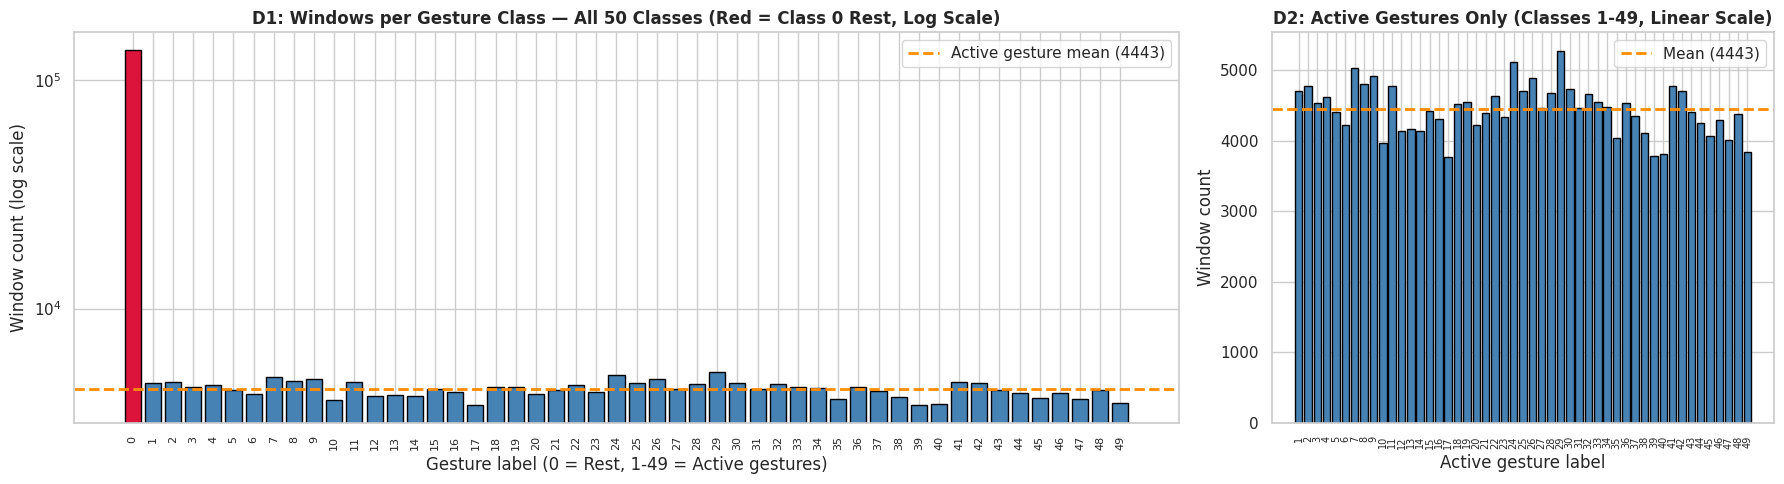

In [7]:
pct = class_counts / len(df) * 100
print(f'Classes: {len(class_counts)} | Majority: label {class_counts.idxmax()} '
      f'({class_counts.max():,}, {pct.max():.1f}%) | Minority: label {class_counts.idxmin()} '
      f'({class_counts.min():,}, {pct.min():.2f}%)')
print(f'Imbalance ratio all classes: {class_counts.max()/class_counts.min():.1f}:1 | '
      f'active gestures only: {active_counts.max()/active_counts.min():.1f}:1')

maj = class_counts.idxmax()
y_true = df.Gesture_Label.values
y_pred = np.full_like(y_true, maj)
print(f'\nBaseline predicting always label {maj}: accuracy = {(y_true==y_pred).mean()*100:.1f}%, '
      f'macro-F1 = {f1_score(y_true, y_pred, average="macro", zero_division=0):.3f}')

colors = ['crimson' if i == 0 else 'steelblue' for i in class_counts.index]
fig, axes = plt.subplots(1, 2, figsize=(18, 5), gridspec_kw={'width_ratios': [2.2, 1]})

axes[0].bar(class_counts.index.astype(str), class_counts.values, color=colors, edgecolor='black', width=0.8)
axes[0].axhline(active_counts.mean(), color='darkorange', ls='--', lw=2,
                label=f'Active gesture mean ({active_counts.mean():.0f})')
axes[0].set_title('D1: Windows per Gesture Class — All 50 Classes (Red = Class 0 Rest, Log Scale)', fontweight='bold')
axes[0].set_xlabel('Gesture label (0 = Rest, 1-49 = Active gestures)')
axes[0].set_ylabel('Window count (log scale)')
axes[0].set_yscale('log')
axes[0].tick_params(axis='x', rotation=90, labelsize=8)
axes[0].legend()

axes[1].bar(active_counts.index.astype(str), active_counts.values, color='steelblue', edgecolor='black', width=0.8)
axes[1].axhline(active_counts.mean(), color='darkorange', ls='--', lw=2,
                label=f'Mean ({active_counts.mean():.0f})')
axes[1].set_title('D2: Active Gestures Only (Classes 1-49, Linear Scale)', fontweight='bold')
axes[1].set_xlabel('Active gesture label')
axes[1].set_ylabel('Window count')
axes[1].tick_params(axis='x', rotation=90, labelsize=7)
axes[1].legend()

plt.tight_layout()
plt.show()

## E. Feature Distributions (histogram, box, violin)

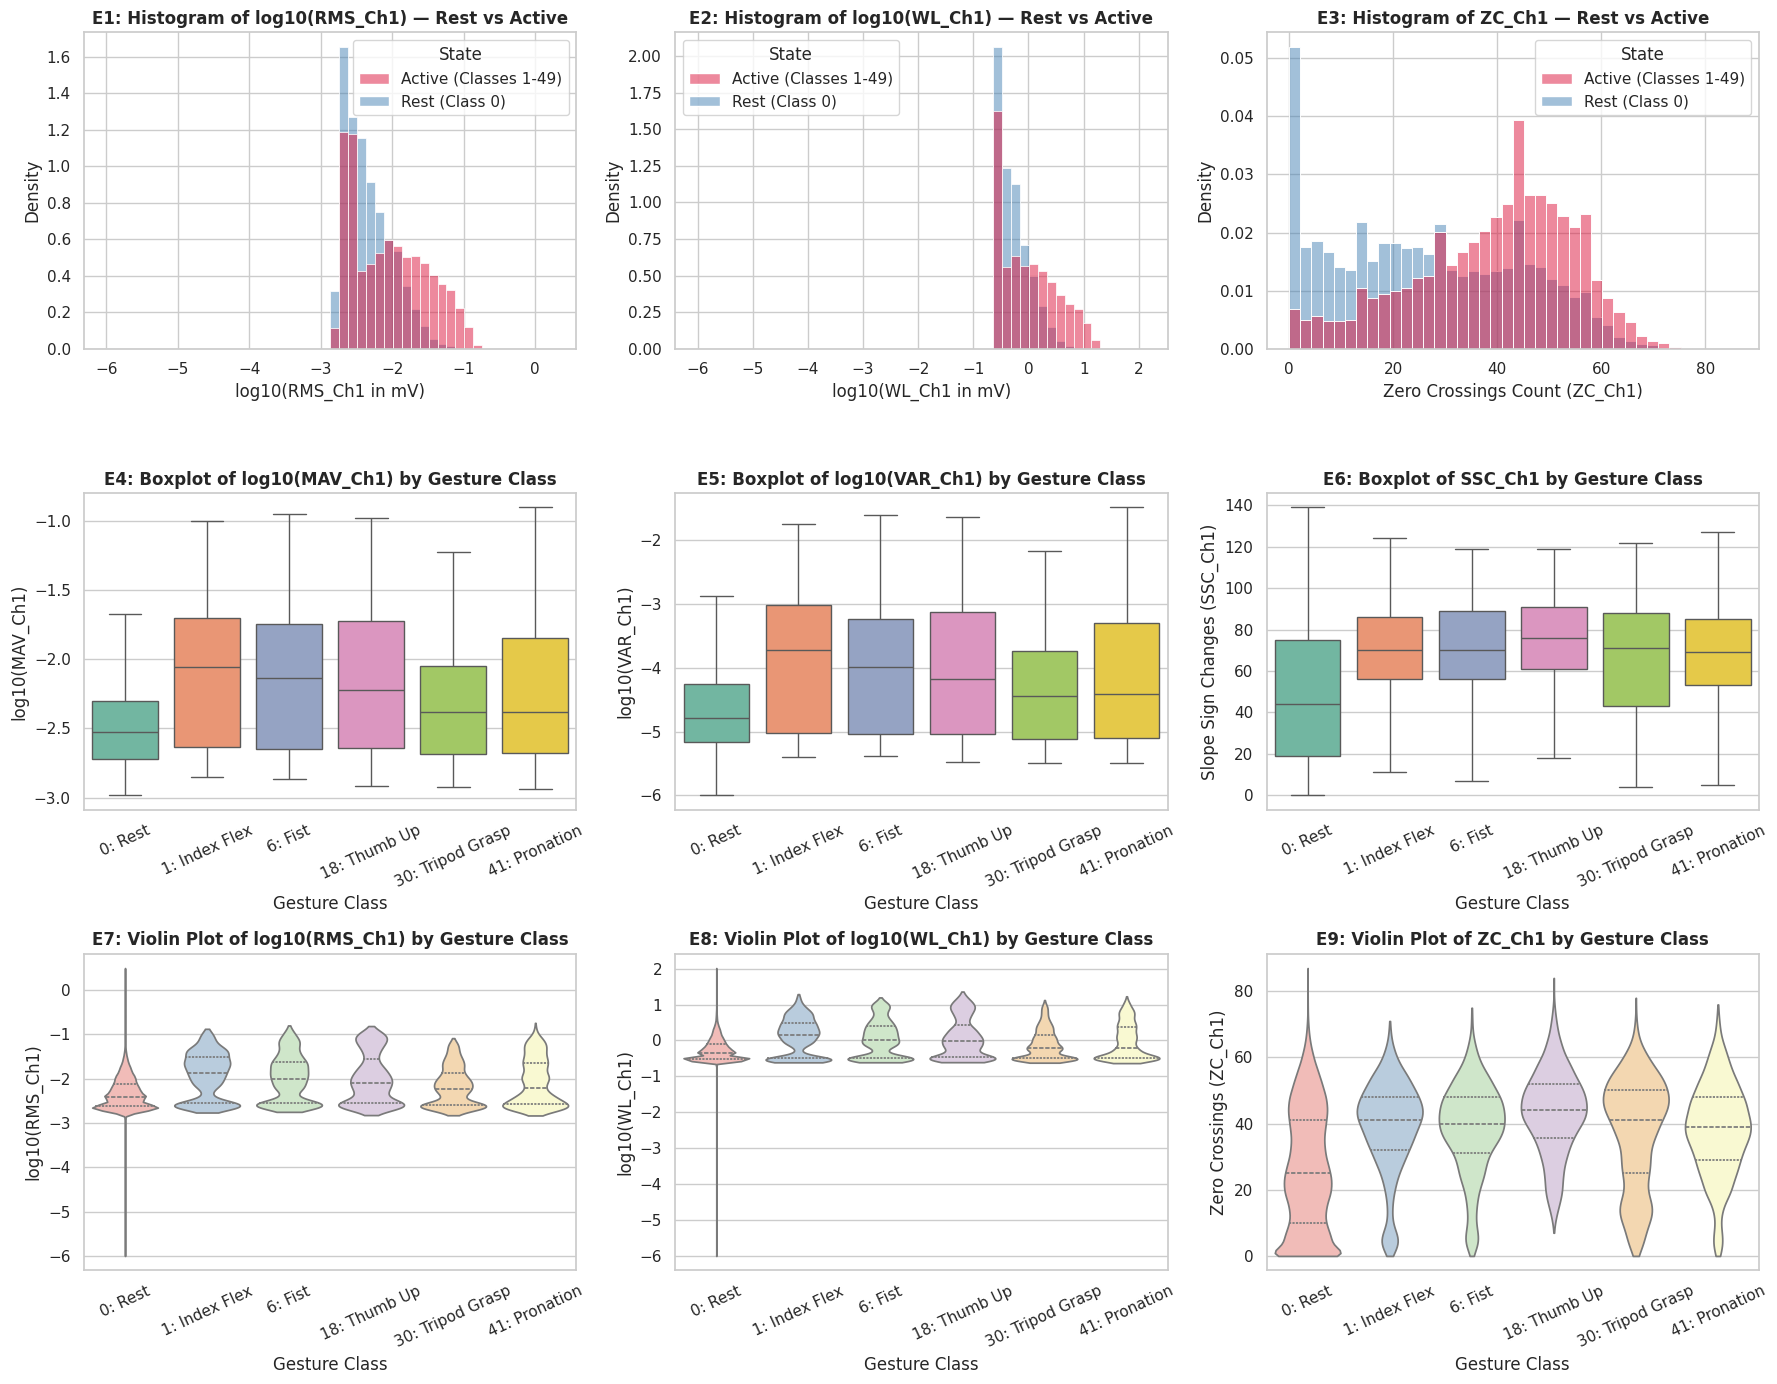

In [8]:
rep_gestures = [0, 1, 6, 18, 30, 41]
rep_names = {0: '0: Rest', 1: '1: Index Flex', 6: '6: Fist', 18: '18: Thumb Up', 30: '30: Tripod Grasp', 41: '41: Pronation'}
df_rep = df[df['Gesture_Label'].isin(rep_gestures)].copy()
df_rep['Gesture_Name'] = df_rep['Gesture_Label'].map(rep_names)

for f in ['MAV_Ch1', 'RMS_Ch1', 'VAR_Ch1', 'WL_Ch1']:
    df_rep[f'log10_{f}'] = np.log10(df_rep[f] + 1e-6)

fig, axes = plt.subplots(3, 3, figsize=(18, 14))

df_sample_hist = df.sample(n=min(50000, len(df)), random_state=42).copy()
df_sample_hist['State'] = np.where(df_sample_hist['Gesture_Label'] == 0, 'Rest (Class 0)', 'Active (Classes 1-49)')
sns.histplot(data=df_sample_hist, x=np.log10(df_sample_hist['RMS_Ch1'] + 1e-6), hue='State',
             stat='density', common_norm=False, bins=50, ax=axes[0, 0], palette=['crimson', 'steelblue'])
axes[0, 0].set_title('E1: Histogram of log10(RMS_Ch1) — Rest vs Active', fontweight='bold')
axes[0, 0].set_xlabel('log10(RMS_Ch1 in mV)')

sns.histplot(data=df_sample_hist, x=np.log10(df_sample_hist['WL_Ch1'] + 1e-6), hue='State',
             stat='density', common_norm=False, bins=50, ax=axes[0, 1], palette=['crimson', 'steelblue'])
axes[0, 1].set_title('E2: Histogram of log10(WL_Ch1) — Rest vs Active', fontweight='bold')
axes[0, 1].set_xlabel('log10(WL_Ch1 in mV)')

sns.histplot(data=df_sample_hist, x='ZC_Ch1', hue='State',
             stat='density', common_norm=False, bins=40, ax=axes[0, 2], palette=['crimson', 'steelblue'])
axes[0, 2].set_title('E3: Histogram of ZC_Ch1 — Rest vs Active', fontweight='bold')
axes[0, 2].set_xlabel('Zero Crossings Count (ZC_Ch1)')

sns.boxplot(data=df_rep, x='Gesture_Name', y='log10_MAV_Ch1', ax=axes[1, 0], palette='Set2', showfliers=False)
axes[1, 0].set_title('E4: Boxplot of log10(MAV_Ch1) by Gesture Class', fontweight='bold')
axes[1, 0].set_xlabel('Gesture Class'); axes[1, 0].set_ylabel('log10(MAV_Ch1)')
axes[1, 0].tick_params(axis='x', rotation=25)

sns.boxplot(data=df_rep, x='Gesture_Name', y='log10_VAR_Ch1', ax=axes[1, 1], palette='Set2', showfliers=False)
axes[1, 1].set_title('E5: Boxplot of log10(VAR_Ch1) by Gesture Class', fontweight='bold')
axes[1, 1].set_xlabel('Gesture Class'); axes[1, 1].set_ylabel('log10(VAR_Ch1)')
axes[1, 1].tick_params(axis='x', rotation=25)

sns.boxplot(data=df_rep, x='Gesture_Name', y='SSC_Ch1', ax=axes[1, 2], palette='Set2', showfliers=False)
axes[1, 2].set_title('E6: Boxplot of SSC_Ch1 by Gesture Class', fontweight='bold')
axes[1, 2].set_xlabel('Gesture Class'); axes[1, 2].set_ylabel('Slope Sign Changes (SSC_Ch1)')
axes[1, 2].tick_params(axis='x', rotation=25)

sns.violinplot(data=df_rep, x='Gesture_Name', y='log10_RMS_Ch1', ax=axes[2, 0], palette='Pastel1', inner='quartile', cut=0)
axes[2, 0].set_title('E7: Violin Plot of log10(RMS_Ch1) by Gesture Class', fontweight='bold')
axes[2, 0].set_xlabel('Gesture Class'); axes[2, 0].set_ylabel('log10(RMS_Ch1)')
axes[2, 0].tick_params(axis='x', rotation=25)

sns.violinplot(data=df_rep, x='Gesture_Name', y='log10_WL_Ch1', ax=axes[2, 1], palette='Pastel1', inner='quartile', cut=0)
axes[2, 1].set_title('E8: Violin Plot of log10(WL_Ch1) by Gesture Class', fontweight='bold')
axes[2, 1].set_xlabel('Gesture Class'); axes[2, 1].set_ylabel('log10(WL_Ch1)')
axes[2, 1].tick_params(axis='x', rotation=25)

sns.violinplot(data=df_rep, x='Gesture_Name', y='ZC_Ch1', ax=axes[2, 2], palette='Pastel1', inner='quartile', cut=0)
axes[2, 2].set_title('E9: Violin Plot of ZC_Ch1 by Gesture Class', fontweight='bold')
axes[2, 2].set_xlabel('Gesture Class'); axes[2, 2].set_ylabel('Zero Crossings (ZC_Ch1)')
axes[2, 2].tick_params(axis='x', rotation=25)

plt.tight_layout()
plt.show()

## F. Correlation Heatmap & Redundant-Feature List

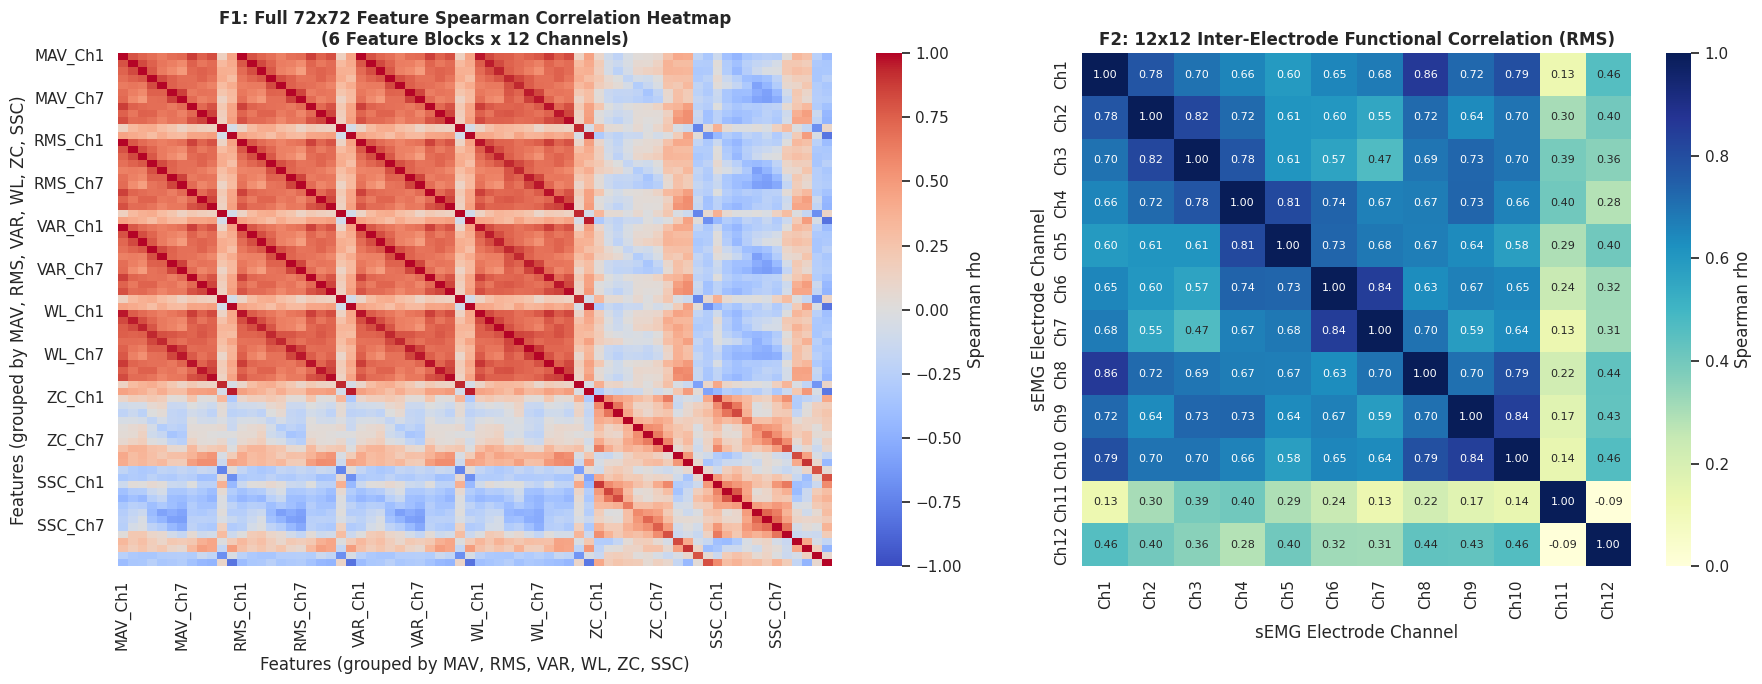

,Feature_1,Feature_2,Spearman_rho
25,RMS_Ch7,VAR_Ch7,0.9999
33,RMS_Ch11,VAR_Ch11,0.9999
21,RMS_Ch5,VAR_Ch5,0.9998
13,RMS_Ch1,VAR_Ch1,0.9998
19,RMS_Ch4,VAR_Ch4,0.9997
15,RMS_Ch2,VAR_Ch2,0.9997
29,RMS_Ch9,VAR_Ch9,0.9997
17,RMS_Ch3,VAR_Ch3,0.9996
35,RMS_Ch12,VAR_Ch12,0.9996
31,RMS_Ch10,VAR_Ch10,0.9992


['RMS_Ch1', 'RMS_Ch10', 'RMS_Ch11', 'RMS_Ch12', 'RMS_Ch2', 'RMS_Ch3', 'RMS_Ch4', 'RMS_Ch5', 'RMS_Ch6', 'RMS_Ch7', 'RMS_Ch8', 'RMS_Ch9', 'VAR_Ch1', 'VAR_Ch10', 'VAR_Ch11', 'VAR_Ch12', 'VAR_Ch2', 'VAR_Ch3', 'VAR_Ch4', 'VAR_Ch5', 'VAR_Ch6', 'VAR_Ch7', 'VAR_Ch8', 'VAR_Ch9', 'WL_Ch1', 'WL_Ch10', 'WL_Ch12', 'WL_Ch2', 'WL_Ch6', 'WL_Ch7', 'WL_Ch8', 'WL_Ch9']


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7), gridspec_kw={'width_ratios': [1.3, 1]})

sns.heatmap(corr_sp, cmap='coolwarm', vmin=-1, vmax=1, center=0,
            xticklabels=6, yticklabels=6, cbar_kws={'label': 'Spearman rho'}, ax=axes[0])
axes[0].set_title('F1: Full 72x72 Feature Spearman Correlation Heatmap\n(6 Feature Blocks x 12 Channels)', fontweight='bold')
axes[0].set_xlabel('Features (grouped by MAV, RMS, VAR, WL, ZC, SSC)')
axes[0].set_ylabel('Features (grouped by MAV, RMS, VAR, WL, ZC, SSC)')

rms_cols = [f'RMS_Ch{c}' for c in range(1, n_channels + 1)]
ch_corr = corr_sp.loc[rms_cols, rms_cols].copy()
ch_corr.index = [f'Ch{c}' for c in range(1, n_channels + 1)]
ch_corr.columns = [f'Ch{c}' for c in range(1, n_channels + 1)]
sns.heatmap(ch_corr, cmap='YlGnBu', vmin=0, vmax=1, annot=True, fmt='.2f',
             annot_kws={'size': 8}, cbar_kws={'label': 'Spearman rho'}, ax=axes[1])
axes[1].set_title('F2: 12x12 Inter-Electrode Functional Correlation (RMS)', fontweight='bold')
axes[1].set_xlabel('sEMG Electrode Channel'); axes[1].set_ylabel('sEMG Electrode Channel')

plt.tight_layout()
plt.show()

df_pairs = pd.DataFrame(pairs, columns=['Feature_1', 'Feature_2', 'Spearman_rho']).sort_values('Spearman_rho', ascending=False)
display(df_pairs.head(20))
df_pairs.to_csv('/content/redundant_feature_pairs.csv', index=False)

to_drop = sorted(list(set(df_pairs['Feature_2'].unique())))
print(to_drop)

## G. 2D/3D Views with PCA, t-SNE, and UMAP

/tmp/ipykernel_405/3449714158.py:2: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_sub = df[df['Gesture_Label'].isin(sub_gestures)].groupby(['Subject_ID', 'Gesture_Label'], group_keys=False).apply(


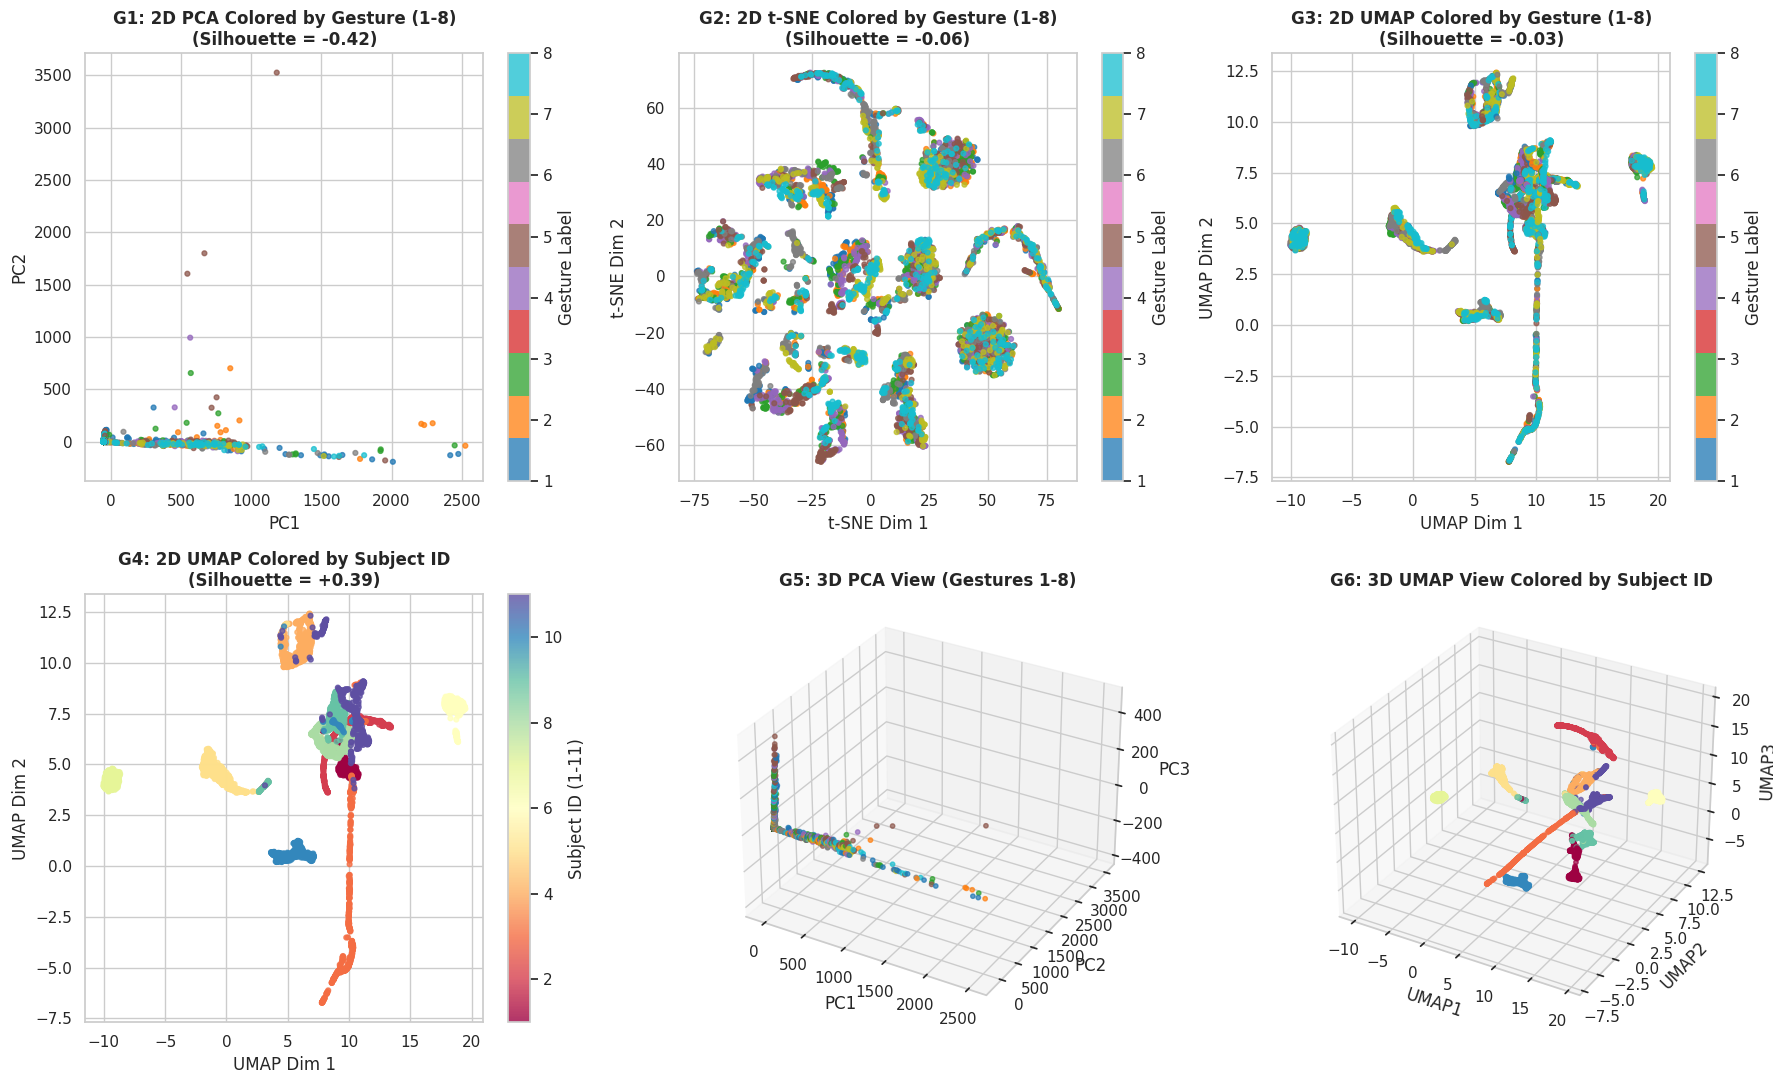

In [10]:
sub_gestures = list(range(1, 9))
df_sub = df[df['Gesture_Label'].isin(sub_gestures)].groupby(['Subject_ID', 'Gesture_Label'], group_keys=False).apply(
    lambda g: g.sample(n=min(60, len(g)), random_state=42)
).reset_index(drop=True)

X_sub = df_sub[feat_cols].copy()
for col in feat_cols:
    if col.startswith(('MAV', 'RMS', 'VAR', 'WL')):
        X_sub[col] = np.log1p(np.maximum(0, X_sub[col]))
X_scaled = RobustScaler().fit_transform(X_sub)

pca_3d = PCA(n_components=3, random_state=42).fit_transform(X_scaled)
tsne_2d = TSNE(n_components=2, perplexity=30, random_state=42, init='pca', learning_rate='auto').fit_transform(X_scaled)
umap_3d = umap.UMAP(n_components=3, n_neighbors=25, min_dist=0.15, random_state=42).fit_transform(X_scaled)

sil_pca_gest  = silhouette_score(pca_3d[:, :2], df_sub['Gesture_Label'])
sil_pca_subj  = silhouette_score(pca_3d[:, :2], df_sub['Subject_ID'])
sil_tsne_gest = silhouette_score(tsne_2d, df_sub['Gesture_Label'])
sil_tsne_subj = silhouette_score(tsne_2d, df_sub['Subject_ID'])
sil_umap_gest = silhouette_score(umap_3d[:, :2], df_sub['Gesture_Label'])
sil_umap_subj = silhouette_score(umap_3d[:, :2], df_sub['Subject_ID'])

fig = plt.figure(figsize=(18, 11))

ax1 = fig.add_subplot(2, 3, 1)
sc1 = ax1.scatter(pca_3d[:, 0], pca_3d[:, 1], c=df_sub['Gesture_Label'], cmap='tab10', s=12, alpha=0.75)
ax1.set_title(f'G1: 2D PCA Colored by Gesture (1-8)\n(Silhouette = {sil_pca_gest:+.2f})', fontweight='bold')
ax1.set_xlabel('PC1'); ax1.set_ylabel('PC2')
plt.colorbar(sc1, ax=ax1, label='Gesture Label')

ax2 = fig.add_subplot(2, 3, 2)
sc2 = ax2.scatter(tsne_2d[:, 0], tsne_2d[:, 1], c=df_sub['Gesture_Label'], cmap='tab10', s=12, alpha=0.75)
ax2.set_title(f'G2: 2D t-SNE Colored by Gesture (1-8)\n(Silhouette = {sil_tsne_gest:+.2f})', fontweight='bold')
ax2.set_xlabel('t-SNE Dim 1'); ax2.set_ylabel('t-SNE Dim 2')
plt.colorbar(sc2, ax=ax2, label='Gesture Label')

ax3 = fig.add_subplot(2, 3, 3)
sc3 = ax3.scatter(umap_3d[:, 0], umap_3d[:, 1], c=df_sub['Gesture_Label'], cmap='tab10', s=12, alpha=0.75)
ax3.set_title(f'G3: 2D UMAP Colored by Gesture (1-8)\n(Silhouette = {sil_umap_gest:+.2f})', fontweight='bold')
ax3.set_xlabel('UMAP Dim 1'); ax3.set_ylabel('UMAP Dim 2')
plt.colorbar(sc3, ax=ax3, label='Gesture Label')

ax4 = fig.add_subplot(2, 3, 4)
sc4 = ax4.scatter(umap_3d[:, 0], umap_3d[:, 1], c=df_sub['Subject_ID'], cmap='Spectral', s=12, alpha=0.8)
ax4.set_title(f'G4: 2D UMAP Colored by Subject ID\n(Silhouette = {sil_umap_subj:+.2f})', fontweight='bold')
ax4.set_xlabel('UMAP Dim 1'); ax4.set_ylabel('UMAP Dim 2')
plt.colorbar(sc4, ax=ax4, label='Subject ID (1-11)')

ax5 = fig.add_subplot(2, 3, 5, projection='3d')
ax5.scatter(pca_3d[:, 0], pca_3d[:, 1], pca_3d[:, 2], c=df_sub['Gesture_Label'], cmap='tab10', s=10, alpha=0.7)
ax5.set_title('G5: 3D PCA View (Gestures 1-8)', fontweight='bold')
ax5.set_xlabel('PC1'); ax5.set_ylabel('PC2'); ax5.set_zlabel('PC3')

ax6 = fig.add_subplot(2, 3, 6, projection='3d')
ax6.scatter(umap_3d[:, 0], umap_3d[:, 1], umap_3d[:, 2], c=df_sub['Subject_ID'], cmap='Spectral', s=10, alpha=0.7)
ax6.set_title('G6: 3D UMAP View Colored by Subject ID', fontweight='bold')
ax6.set_xlabel('UMAP1'); ax6.set_ylabel('UMAP2'); ax6.set_zlabel('UMAP3')

plt.tight_layout()
plt.show()

## H. Interactive Plots (Plotly)

In [11]:
df_plot = df_sub[['Subject_ID', 'Gesture_Label', 'RMS_Ch1']].copy()
df_plot['UMAP_1'] = umap_3d[:, 0]
df_plot['UMAP_2'] = umap_3d[:, 1]
df_plot['UMAP_3'] = umap_3d[:, 2]
df_plot['Subject_Str'] = 'Subject ' + df_plot['Subject_ID'].astype(str)
df_plot['Gesture_Str'] = 'Gesture ' + df_plot['Gesture_Label'].astype(str)

fig_h1 = px.scatter_3d(
    df_plot, x='UMAP_1', y='UMAP_2', z='UMAP_3',
    color='Subject_Str', symbol='Gesture_Str',
    hover_data=['Subject_ID', 'Gesture_Label', 'RMS_Ch1'],
    title='H1 (Interactive 3D UMAP): Amputee Subject Islands vs. Local Gesture Sub-Clusters (Gestures 1-8)',
    labels={'UMAP_1': 'UMAP Dim 1', 'UMAP_2': 'UMAP Dim 2', 'UMAP_3': 'UMAP Dim 3'},
    height=600
)
fig_h1.update_traces(marker=dict(size=4, opacity=0.8))
fig_h1.show()

rms_profile = df[df['Gesture_Label'].isin(rep_gestures)].groupby('Gesture_Label')[rms_cols].median().reset_index()
rms_profile['Gesture_Name'] = rms_profile['Gesture_Label'].map(rep_names)
rms_melted = rms_profile.melt(id_vars=['Gesture_Label', 'Gesture_Name'], value_vars=rms_cols,
                              var_name='Electrode', value_name='Median_RMS_mV')
rms_melted['Electrode'] = rms_melted['Electrode'].str.replace('RMS_', '')

fig_h2 = px.line(
    rms_melted, x='Electrode', y='Median_RMS_mV', color='Gesture_Name', markers=True,
    title='H2 (Interactive Electrode Profile): Median sEMG RMS Activation Across All 12 Forearm Channels by Gesture',
    labels={'Electrode': 'sEMG Electrode Channel (Ch1 - Ch12)', 'Median_RMS_mV': 'Median RMS Amplitude (mV)'},
    height=480
)
fig_h2.show()